# Spatio-Temporal Facial Emotion Recognition on RAVDESS
**Auteur :** Mohammed EL Makhloufi (Master Machine Learning & Multimedia Intelligence — USMBA Fès)  
**Dépôt GitHub :** `https://github.com/MDMAK04/Facial-Emotion-Recognition-SpatioTemporal`

### Objectifs du Projet :
1. **Protocole strict indépendant des acteurs (*Actor-Independent Split*)** : Entraînement sur les acteurs `01–19` (80%) et évaluation sur les acteurs `20–24` (20%) afin d'éviter toute fuite de données.
2. **Sélection intelligente de Keyframes (Anti-Redondance)** : Recadrage facial automatique couplé à un filtrage par similarité structurelle (**SSIM**) pour éliminer les images redondantes avant l'extraction spatiale.
3. **Extraction Spatiale (Stage 1)** : Fine-tuning d'un backbone **VGG16** pré-entraîné sur ImageNet pour extraire des vecteurs latents discriminants de dimension `512`.
4. **Étude Comparative des Modèles Séquentiels (Stage 2)** : Benchmark rigoureux entre le vote majoritaire (*Majority Voting*, baseline de l'article) et quatre architectures temporelles (**RNN, LSTM, GRU, Transformer**).

## 1. Configuration de l'environnement GPU et Importation du Code Modulaire (`src/`)

In [2]:
!rm -rf repo
!git clone https://github.com/MDMAK04/Facial-Emotion-Recognition-SpatioTemporal.git repo
%cd repo
!pip install -q -r requirements.txt

Cloning into 'repo'...
remote: Enumerating objects: 35, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (24/24), done.
remote: Total 35 (delta 9), reused 34 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (35/35), 11.39 KiB | 2.85 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/content/repo


In [2]:
import os, sys, yaml
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import mode
from joblib import Parallel, delayed
from tqdm import tqdm
from google.colab import drive

drive.mount("/content/drive")
CACHE_DIR = "/content/drive/MyDrive/RAVDESS_cache"
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs("report", exist_ok=True)

sys.path.insert(0, os.getcwd())
with open("configs/config.yaml", "r") as f:
    cfg = yaml.safe_load(f)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil d'entraînement :", device)

Mounted at /content/drive
Appareil d'entraînement : cuda


## 2. Acquisition des Données (RAVDESS Video Speech — 1 440 vidéos)
Téléchargement automatisé des 24 acteurs depuis le dépôt officiel Zenodo (`record/1188976`).

In [3]:
import zipfile, subprocess
from concurrent.futures import ThreadPoolExecutor

DATA_DIR = cfg["dataset"]["raw_dir"]
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs("data/zips", exist_ok=True)
base_url = "https://zenodo.org/api/records/1188976/files/Video_Speech_Actor_{:02d}.zip/content"

def download_and_extract(actor_id):
    actor_dir = os.path.join(DATA_DIR, f"Actor_{actor_id:02d}")
    zip_path = f"data/zips/Video_Speech_Actor_{actor_id:02d}.zip"
    if os.path.exists(actor_dir) and len(os.listdir(actor_dir)) >= 60:
        return
    url = base_url.format(actor_id)
    subprocess.run(["wget", "-q", "-c", "--tries=10", url, "-O", zip_path], check=True)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_DIR)
    os.remove(zip_path)

if not os.path.exists(os.path.join(CACHE_DIR, "X_train_frames.npy")):
    print("Téléchargement parallèle des 24 acteurs RAVDESS...")
    with ThreadPoolExecutor(max_workers=4) as ex:
        list(tqdm(ex.map(download_and_extract, range(1, 25)), total=24))
    print("Téléchargement terminé !")
else:
    print("Cache déjà détecté sur Google Drive, téléchargement ignoré.")

Téléchargement parallèle des 24 acteurs RAVDESS...


100%|██████████| 24/24 [32:53<00:00, 82.23s/it]

Téléchargement terminé !


## 3. Partitionnement Actor-Independent et Sélection Intelligente de Keyframes (Anti-Redondance)

Cette étape implémente le prétraitement spatio-temporel des **1 440 vidéos uniques** du dataset RAVDESS (*Speech*) :
1. **Protocole strict indépendant des acteurs (*Actor-Independent Split*)** : Séparation entre les acteurs `01–19` (Entraînement, 1 140 vidéos) et les acteurs `20–24` (Validation/Test, 300 vidéos) afin d'éviter toute fuite d'identité (*subject leakage*).
2. **Détection et recadrage facial (*Face ROI Cropping*)** : Isolation automatique de la région du visage redimensionnée en `128 × 128 × 3` pour supprimer le bruit de l'arrière-plan.
3. **Filtrage de redondance par Similarité Structurelle (SSIM)** : Élimination des frames consécutives quasi-identiques ($\text{SSIM} \ge 0.90$) afin de ne conserver que les images porteuses de variations expressives significatives, normalisées à une séquence fixe de $T = 16$ keyframes par vidéo.


In [4]:
from src.dataset_parser import parse_ravdess_directory
from src.keyframe_selector import KeyframeSelector

cache_files = ["X_train_frames.npy", "y_train_videos.npy", "X_val_frames.npy", "y_val_videos.npy"]

if all(os.path.exists(os.path.join(CACHE_DIR, f)) for f in cache_files):
    X_train_frames = np.load(os.path.join(CACHE_DIR, "X_train_frames.npy"))
    y_train_videos = np.load(os.path.join(CACHE_DIR, "y_train_videos.npy"))
    X_val_frames   = np.load(os.path.join(CACHE_DIR, "X_val_frames.npy"))
    y_val_videos   = np.load(os.path.join(CACHE_DIR, "y_val_videos.npy"))
    print("Tenseurs chargés depuis Google Drive !")
else:
    df = parse_ravdess_directory(DATA_DIR, train_actors_max=cfg["dataset"]["train_actors_max"])
    print(f"Vidéos uniques : {len(df)} | Train : {(df['split']=='train').sum()} | Val : {(df['split']=='val').sum()}")

    selector = KeyframeSelector(
        img_size=tuple(cfg["dataset"]["img_size"]),
        ssim_threshold=cfg["dataset"]["ssim_threshold"],
        target_frames=cfg["dataset"]["target_frames"],
        crop_face=cfg["dataset"]["crop_face"]
    )

    results = Parallel(n_jobs=-1, prefer="threads")(
        delayed(selector.extract_keyframes)(path) for path in tqdm(df["video_path"])
    )

    X_train_frames = np.array([r[0] for r, s in zip(results, df["split"]) if s == "train"], dtype=np.uint8)
    y_train_videos = df[df["split"] == "train"]["label"].values
    X_val_frames   = np.array([r[0] for r, s in zip(results, df["split"]) if s == "val"], dtype=np.uint8)
    y_val_videos   = df[df["split"] == "val"]["label"].values

    np.save(os.path.join(CACHE_DIR, "X_train_frames.npy"), X_train_frames)
    np.save(os.path.join(CACHE_DIR, "y_train_videos.npy"), y_train_videos)
    np.save(os.path.join(CACHE_DIR, "X_val_frames.npy"), X_val_frames)
    np.save(os.path.join(CACHE_DIR, "y_val_videos.npy"), y_val_videos)

    stats_df = pd.DataFrame([r[1] for r in results])
    print(f"Frames brutes moyennes : {stats_df['total_raw_frames'].mean():.1f}")
    print(f"Frames après SSIM      : {stats_df['after_ssim_filtering'].mean():.1f}")
    print(f"Redondance éliminée    : {stats_df['reduction_ratio'].mean()*100:.1f}%")

print(f"Tenseurs prêts : Train {X_train_frames.shape} | Val {X_val_frames.shape}")

Vidéos uniques : 1440 | Train : 1140 | Val : 300


100%|██████████| 1440/1440 [16:36<00:00,  1.45it/s]


Frames brutes moyennes : 110.6
Frames après SSIM      : 38.0
Redondance éliminée    : 66.0%
Tenseurs prêts : Train (1140, 16, 128, 128, 3) | Val (300, 16, 128, 128, 3)


### 4. Configuration et Chargement des Tenseurs depuis Google Drive
Montage de Google Drive, chargement de la configuration (`config.yaml`) et récupération des tenseurs d'images filtrés par SSIM (`uint8`).

In [3]:
import os, sys, gc, yaml
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import mode

if os.path.exists("/content/repo"):
    os.chdir("/content/repo")
sys.path.insert(0, os.getcwd())

with open("configs/config.yaml", "r") as f:
    cfg = yaml.safe_load(f)

CACHE_DIR = "/content/drive/MyDrive/RAVDESS_cache"

from src.spatial_extractor import SpatialFeatureExtractor
from src.evaluate import evaluate_predictions, plot_confusion_matrix

X_train_frames = np.load(os.path.join(CACHE_DIR, "X_train_frames.npy"))
y_train_videos = np.load(os.path.join(CACHE_DIR, "y_train_videos.npy"))
X_val_frames   = np.load(os.path.join(CACHE_DIR, "X_val_frames.npy"))
y_val_videos   = np.load(os.path.join(CACHE_DIR, "y_val_videos.npy"))

N_tr, T, H, W, C = X_train_frames.shape
N_va = X_val_frames.shape[0]
print(f"Tenseurs chargés : Train {X_train_frames.shape} | Val {X_val_frames.shape}")

Tenseurs chargés : Train (1140, 16, 128, 128, 3) | Val (300, 16, 128, 128, 3)


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### 4-1. Préparation des DataLoaders Légers (`LazyFrameDataset`)
Création des DataLoaders PyTorch qui conservent les images en `uint8` et normalisent chaque batch à la volée pour éviter toute saturation de la RAM CPU.

In [6]:
class LazyFrameDataset(Dataset):
    def __init__(self, frames_5d, video_labels):
        self.frames = frames_5d.reshape(-1, H, W, C)
        self.labels = np.repeat(video_labels, T)
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        self.std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = torch.from_numpy(self.frames[idx]).permute(2, 0, 1).float() / 255.0
        img = (img - self.mean) / self.std
        return img, torch.tensor(self.labels[idx], dtype=torch.long)

bs_sp = cfg["spatial"]["batch_size"]
train_loader = DataLoader(LazyFrameDataset(X_train_frames, y_train_videos), batch_size=bs_sp, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(LazyFrameDataset(X_val_frames, y_val_videos), batch_size=bs_sp, shuffle=False, num_workers=2, pin_memory=True)

class_weights = compute_class_weight("balanced", classes=np.unique(y_train_videos), y=y_train_videos)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32).to(device))
print("DataLoaders prêts !")

DataLoaders prêts !


### 4-2. Stage 1 : Entraînement Spatial (`VGG16`)
Fine-tuning du réseau convolutif `VGG16` image par image avec sauvegarde automatique des meilleurs poids (`best_spatial_vgg16.pth`) sur Google Drive.

In [ ]:
spatial_model = SpatialFeatureExtractor(
    backbone=cfg["spatial"]["backbone"],
    num_classes=cfg["spatial"]["num_classes"],
    feature_dim=cfg["spatial"]["feature_dim"],
    freeze_early_layers=cfg["spatial"]["freeze_early_layers"]
).to(device)

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, spatial_model.parameters()),
    lr=cfg["spatial"]["lr"],
    weight_decay=cfg["spatial"]["weight_decay"]
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

best_frame_acc = 0.0
for epoch in range(cfg["spatial"]["epochs"]):
    spatial_model.train()
    tr_corr, tr_tot = 0, 0
    for bx, by in train_loader:
        bx, by = bx.to(device, non_blocking=True), by.to(device, non_blocking=True)
        if torch.rand(1).item() > 0.5:
            bx = torch.flip(bx, dims=[3])
        optimizer.zero_grad()
        out = spatial_model(bx)
        loss = criterion(out, by)
        loss.backward()
        optimizer.step()
        tr_corr += (out.argmax(1) == by).sum().item()
        tr_tot += by.size(0)

    spatial_model.eval()
    va_corr, va_tot = 0, 0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device, non_blocking=True), by.to(device, non_blocking=True)
            va_corr += (spatial_model(bx).argmax(1) == by).sum().item()
            va_tot += by.size(0)

    val_acc = va_corr / va_tot
    scheduler.step(val_acc)
    if val_acc > best_frame_acc:
        best_frame_acc = val_acc
        torch.save(spatial_model.state_dict(), os.path.join(CACHE_DIR, "best_spatial_vgg16.pth"))
    print(f"Epoch {epoch+1:02d}/{cfg['spatial']['epochs']} | Train Acc: {tr_corr/tr_tot*100:.2f}% | Val Acc: {val_acc*100:.2f}%")

### 4-3. Évaluation Baseline (`Majority Voting`) et Extraction des Séquences Latentes
Évaluation par vote majoritaire vidéo, affichage de la matrice de confusion et extraction des séquences de caractéristiques `(N, 16, 512)` pour l'entraînement temporel (Stage 2).

In [ ]:
spatial_model.load_state_dict(torch.load(os.path.join(CACHE_DIR, "best_spatial_vgg16.pth"), map_location=device))
spatial_model.eval()

val_frame_preds = []
with torch.no_grad():
    for bx, _ in val_loader:
        val_frame_preds.append(spatial_model(bx.to(device)).argmax(1).cpu().numpy())
val_frame_preds = np.concatenate(val_frame_preds)
val_video_majority = mode(val_frame_preds.reshape(N_va, T), axis=1, keepdims=False)[0]
y_va_flat_np = np.repeat(y_val_videos, T)

benchmark_results = [
    evaluate_predictions(y_va_flat_np, val_frame_preds, "VGG16 (Frame-Level)"),
    evaluate_predictions(y_val_videos, val_video_majority, "VGG16 + Majority Voting (Baseline)")
]
plot_confusion_matrix(y_val_videos, val_video_majority, "VGG16 + Majority Voting", os.path.join(CACHE_DIR, "cm_majority_voting.png"))

def extract_latent_sequences(frames_5d, video_labels, num_videos):
    seq_loader = DataLoader(LazyFrameDataset(frames_5d, video_labels), batch_size=bs_sp, shuffle=False, num_workers=2)
    feats = []
    with torch.no_grad():
        for bx, _ in seq_loader:
            feats.append(spatial_model.extract_features(bx.to(device)).cpu().numpy())
    return np.concatenate(feats, axis=0).reshape(num_videos, T, -1)

X_train_seq = extract_latent_sequences(X_train_frames, y_train_videos, N_tr)
X_val_seq   = extract_latent_sequences(X_val_frames, y_val_videos, N_va)
np.save(os.path.join(CACHE_DIR, "X_train_seq.npy"), X_train_seq)
np.save(os.path.join(CACHE_DIR, "X_val_seq.npy"), X_val_seq)

del X_train_frames, X_val_frames
gc.collect()
print(f"Séquences latentes extraites : Train {X_train_seq.shape} | Val {X_val_seq.shape}")

## 5. Stage 2 : Modélisation Temporelle et Benchmark Comparatif (`RNN`, `LSTM`, `GRU`, `Transformer`)
Entraînement des quatre architectures séquentielles sur les vecteurs latents `(N, 16, 512)`, génération du tableau comparatif final (`benchmark_results.csv`) et de la matrice de confusion du meilleur modèle.

### 5-1. Chargement des Séquences Latentes depuis Google Drive
Montage de Google Drive, chargement de la configuration (`config.yaml`) et récupération des vecteurs latents `(1140, 16, 512)` et `(300, 16, 512)`.

In [18]:
import os, sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
from google.colab import drive

drive.mount("/content/drive")
if not os.path.exists("/content/repo"):
    !git clone https://github.com/MDMAK04/Facial-Emotion-Recognition-SpatioTemporal.git /content/repo
os.chdir("/content/repo")
sys.path.insert(0, os.getcwd())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CACHE_DIR = "/content/drive/MyDrive/RAVDESS_cache"

from src.sequence_models import TemporalSequenceClassifier
from src.evaluate import evaluate_predictions, plot_confusion_matrix

# Chargement des séquences latentes
X_train_seq    = np.load(os.path.join(CACHE_DIR, "X_train_seq.npy"))
X_val_seq      = np.load(os.path.join(CACHE_DIR, "X_val_seq.npy"))
y_train_videos = np.load(os.path.join(CACHE_DIR, "y_train_videos.npy"))
y_val_videos   = np.load(os.path.join(CACHE_DIR, "y_val_videos.npy"))

# DataLoaders & Perte pondérée avec Label Smoothing
BATCH_SIZE = 32
seq_train_loader = DataLoader(TensorDataset(torch.from_numpy(X_train_seq).float(), torch.from_numpy(y_train_videos).long()), batch_size=BATCH_SIZE, shuffle=True)
seq_val_loader   = DataLoader(TensorDataset(torch.from_numpy(X_val_seq).float(), torch.from_numpy(y_val_videos).long()), batch_size=BATCH_SIZE, shuffle=False)

class_weights = compute_class_weight("balanced", classes=np.unique(y_train_videos), y=y_train_videos)
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32).to(device),
    label_smoothing=0.1
)

# Dictionnaire global pour stocker les résultats de chaque modèle
results_dict = {}

def train_temporal_model(model_type, hidden_dim, num_layers, dropout, lr, weight_decay, epochs):
    model = TemporalSequenceClassifier(
        model_type=model_type,
        input_dim=512,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        num_classes=8,
        dropout=dropout
    ).to(device)

    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    print(f"=== Entraînement : VGG16 + {model_type.upper()} ===")
    best_acc, best_preds = 0.0, None
    for epoch in range(epochs):
        model.train()
        tr_loss, tr_corr, tr_tot = 0.0, 0, 0
        for bx, by in seq_train_loader:
            bx, by = bx.to(device), by.to(device)
            # Régularisation sur les séquences latentes pour éviter la mémorisation des acteurs 01-19
            bx = F.dropout(bx, p=0.3, training=True)
            bx = bx + 0.05 * torch.randn_like(bx)

            opt.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            opt.step()

            tr_loss += loss.item() * by.size(0)
            tr_corr += (out.argmax(1) == by).sum().item()
            tr_tot += by.size(0)
        sched.step()

        model.eval()
        preds = []
        with torch.no_grad():
            for bx, _ in seq_val_loader:
                preds.append(model(bx.to(device)).argmax(1).cpu().numpy())
        preds = np.concatenate(preds)
        acc = (preds == y_val_videos).mean()

        save_tag = ""
        if acc > best_acc:
            best_acc = acc
            best_preds = preds
            torch.save(model.state_dict(), os.path.join(CACHE_DIR, f"best_vgg16_{model_type}.pth"))
            save_tag = "  <-- Best"

        print(f"Epoch {epoch+1:02d}/{epochs} | Loss: {tr_loss/tr_tot:.4f} | Train Acc: {tr_corr/tr_tot*100:.2f}% | Val Acc: {acc*100:.2f}%{save_tag}")

    label = f"VGG16 + {model_type.upper()}"
    metrics = evaluate_predictions(y_val_videos, best_preds, label)
    results_dict[label] = {"metrics": metrics, "acc": best_acc, "preds": best_preds}
    print(f"\n[{label}] Terminé -> Meilleure Val Acc : {best_acc*100:.2f}%\n")

print(f"Prêt sur {device} | Train : {X_train_seq.shape} | Val : {X_val_seq.shape}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Prêt sur cpu | Train : (1140, 16, 512) | Val : (300, 16, 512)


### 5-2. Entraînement du Modèle 1 : `VGG16 + RNN`
Entraînement du réseau récurrent simple (`RNN`) avec ses hyperparamètres dédiés.

In [19]:
train_temporal_model(
    model_type="rnn",
    hidden_dim=128,
    num_layers=2,
    dropout=0.3,
    lr=0.001,
    weight_decay=1e-4,
    epochs=30
)

=== Entraînement : VGG16 + RNN ===
Epoch 01/30 | Loss: 0.6404 | Train Acc: 95.09% | Val Acc: 58.67%  <-- Best
Epoch 02/30 | Loss: 0.5094 | Train Acc: 100.00% | Val Acc: 59.67%  <-- Best
Epoch 03/30 | Loss: 0.5038 | Train Acc: 100.00% | Val Acc: 59.33%
Epoch 04/30 | Loss: 0.5012 | Train Acc: 100.00% | Val Acc: 59.33%
Epoch 05/30 | Loss: 0.4999 | Train Acc: 100.00% | Val Acc: 60.00%  <-- Best
Epoch 06/30 | Loss: 0.4993 | Train Acc: 100.00% | Val Acc: 59.33%
Epoch 07/30 | Loss: 0.4969 | Train Acc: 100.00% | Val Acc: 59.00%
Epoch 08/30 | Loss: 0.4960 | Train Acc: 100.00% | Val Acc: 60.33%  <-- Best
Epoch 09/30 | Loss: 0.4953 | Train Acc: 100.00% | Val Acc: 59.00%
Epoch 10/30 | Loss: 0.4949 | Train Acc: 100.00% | Val Acc: 59.67%
Epoch 11/30 | Loss: 0.4948 | Train Acc: 100.00% | Val Acc: 59.67%
Epoch 12/30 | Loss: 0.4938 | Train Acc: 100.00% | Val Acc: 59.33%
Epoch 13/30 | Loss: 0.4935 | Train Acc: 100.00% | Val Acc: 60.00%
Epoch 14/30 | Loss: 0.4925 | Train Acc: 100.00% | Val Acc: 59.67%
Ep

### 5-3. Entraînement du Modèle 2 : `VGG16 + LSTM`
Entraînement du réseau `LSTM` avec ses hyperparamètres dédiés.

In [20]:
train_temporal_model(
    model_type="lstm",
    hidden_dim=128,
    num_layers=2,
    dropout=0.35,
    lr=0.0008,
    weight_decay=1e-4,
    epochs=35
)

=== Entraînement : VGG16 + LSTM ===
Epoch 01/35 | Loss: 0.6269 | Train Acc: 95.53% | Val Acc: 58.67%  <-- Best
Epoch 02/35 | Loss: 0.5074 | Train Acc: 100.00% | Val Acc: 59.33%  <-- Best
Epoch 03/35 | Loss: 0.5022 | Train Acc: 100.00% | Val Acc: 58.33%
Epoch 04/35 | Loss: 0.4990 | Train Acc: 100.00% | Val Acc: 59.67%  <-- Best
Epoch 05/35 | Loss: 0.4981 | Train Acc: 100.00% | Val Acc: 59.67%
Epoch 06/35 | Loss: 0.4967 | Train Acc: 100.00% | Val Acc: 59.67%
Epoch 07/35 | Loss: 0.4961 | Train Acc: 100.00% | Val Acc: 59.33%
Epoch 08/35 | Loss: 0.4949 | Train Acc: 100.00% | Val Acc: 59.00%
Epoch 09/35 | Loss: 0.4945 | Train Acc: 100.00% | Val Acc: 59.33%
Epoch 10/35 | Loss: 0.4941 | Train Acc: 100.00% | Val Acc: 59.33%
Epoch 11/35 | Loss: 0.4933 | Train Acc: 100.00% | Val Acc: 59.33%
Epoch 12/35 | Loss: 0.4930 | Train Acc: 100.00% | Val Acc: 60.00%  <-- Best
Epoch 13/35 | Loss: 0.4934 | Train Acc: 100.00% | Val Acc: 59.67%
Epoch 14/35 | Loss: 0.4930 | Train Acc: 100.00% | Val Acc: 59.67%
E

### 5-4. Entraînement du Modèle 3 : `VGG16 + GRU`
Entraînement du réseau `GRU` avec ses hyperparamètres dédiés.

In [21]:
train_temporal_model(
    model_type="gru",
    hidden_dim=128,
    num_layers=2,
    dropout=0.3,
    lr=0.001,
    weight_decay=1e-4,
    epochs=35
)

=== Entraînement : VGG16 + GRU ===
Epoch 01/35 | Loss: 0.6469 | Train Acc: 95.96% | Val Acc: 59.00%  <-- Best
Epoch 02/35 | Loss: 0.5097 | Train Acc: 100.00% | Val Acc: 60.33%  <-- Best
Epoch 03/35 | Loss: 0.5050 | Train Acc: 100.00% | Val Acc: 61.00%  <-- Best
Epoch 04/35 | Loss: 0.5020 | Train Acc: 100.00% | Val Acc: 61.00%
Epoch 05/35 | Loss: 0.4989 | Train Acc: 100.00% | Val Acc: 60.67%
Epoch 06/35 | Loss: 0.4982 | Train Acc: 100.00% | Val Acc: 60.33%
Epoch 07/35 | Loss: 0.4973 | Train Acc: 100.00% | Val Acc: 61.00%
Epoch 08/35 | Loss: 0.4958 | Train Acc: 100.00% | Val Acc: 62.00%  <-- Best
Epoch 09/35 | Loss: 0.4947 | Train Acc: 100.00% | Val Acc: 61.67%
Epoch 10/35 | Loss: 0.4949 | Train Acc: 100.00% | Val Acc: 61.33%
Epoch 11/35 | Loss: 0.4931 | Train Acc: 100.00% | Val Acc: 61.33%
Epoch 12/35 | Loss: 0.4929 | Train Acc: 100.00% | Val Acc: 60.67%
Epoch 13/35 | Loss: 0.4925 | Train Acc: 100.00% | Val Acc: 61.33%
Epoch 14/35 | Loss: 0.4925 | Train Acc: 100.00% | Val Acc: 62.33%  <

### 5-5. Entraînement du Modèle 4 : `VGG16 + Transformer`
Entraînement de l'encodeur `Transformer` avec ses hyperparamètres dédiés.

In [22]:
train_temporal_model(
    model_type="transformer",
    hidden_dim=128,
    num_layers=2,
    dropout=0.35,
    lr=0.0003,
    weight_decay=5e-4,
    epochs=45
)

=== Entraînement : VGG16 + TRANSFORMER ===
Epoch 01/45 | Loss: 0.7809 | Train Acc: 90.09% | Val Acc: 57.67%  <-- Best
Epoch 02/45 | Loss: 0.5256 | Train Acc: 100.00% | Val Acc: 58.33%  <-- Best
Epoch 03/45 | Loss: 0.5199 | Train Acc: 100.00% | Val Acc: 59.67%  <-- Best
Epoch 04/45 | Loss: 0.5168 | Train Acc: 100.00% | Val Acc: 58.33%
Epoch 05/45 | Loss: 0.5147 | Train Acc: 100.00% | Val Acc: 59.00%
Epoch 06/45 | Loss: 0.5125 | Train Acc: 100.00% | Val Acc: 60.67%  <-- Best
Epoch 07/45 | Loss: 0.5116 | Train Acc: 100.00% | Val Acc: 59.00%
Epoch 08/45 | Loss: 0.5089 | Train Acc: 100.00% | Val Acc: 59.00%
Epoch 09/45 | Loss: 0.5091 | Train Acc: 100.00% | Val Acc: 59.00%
Epoch 10/45 | Loss: 0.5077 | Train Acc: 100.00% | Val Acc: 60.67%
Epoch 11/45 | Loss: 0.5061 | Train Acc: 100.00% | Val Acc: 59.33%
Epoch 12/45 | Loss: 0.5060 | Train Acc: 100.00% | Val Acc: 60.33%
Epoch 13/45 | Loss: 0.5051 | Train Acc: 100.00% | Val Acc: 60.33%
Epoch 14/45 | Loss: 0.5037 | Train Acc: 100.00% | Val Acc: 6

### 5-6. Tableau Comparatif Final et Matrice de Confusion du Meilleur Modèle
Affichage du tableau comparatif de tous les modèles entraînés et tracé de la matrice de confusion du meilleur modèle spatio-temporel.

,Model,Accuracy (%),F1-Macro (%),Precision (%),Recall (%)
0,VGG16 + RNN,60.33,57.56,63.32,59.06
1,VGG16 + LSTM,60.33,57.84,63.64,58.75
2,VGG16 + GRU,62.33,59.71,64.84,60.94
3,VGG16 + TRANSFORMER,61.33,59.40,63.88,60.63


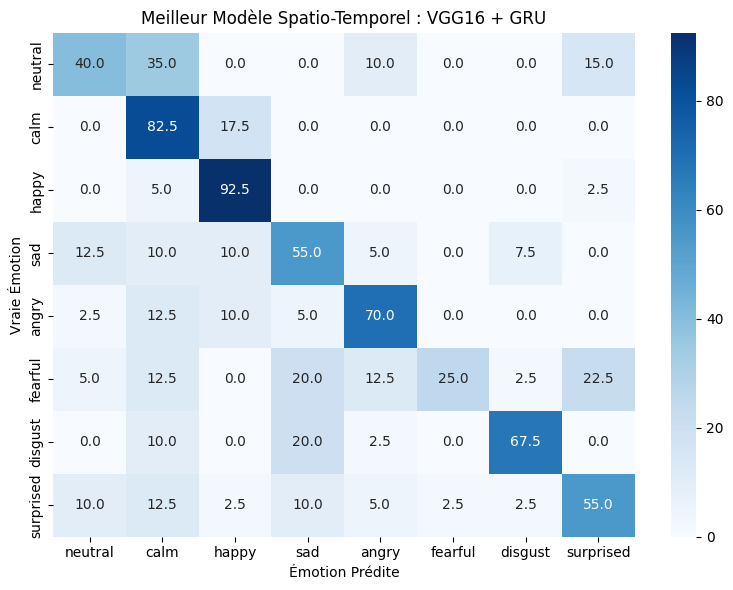

In [23]:
results_df = pd.DataFrame([v["metrics"] for v in results_dict.values()])
results_df.to_csv(os.path.join(CACHE_DIR, "benchmark_results.csv"), index=False)
display(results_df)

best_label = max(results_dict, key=lambda k: results_dict[k]["acc"])
best_preds = results_dict[best_label]["preds"]

plot_confusion_matrix(
    y_val_videos,
    best_preds,
    f"Meilleur Modèle Spatio-Temporel : {best_label}",
    os.path.join(CACHE_DIR, "cm_best_spatiotemporal.png")
)